In [12]:
!pip -q install datasets

from datasets import load_dataset

dataset = load_dataset("lukebarousse/data_jobs", split="train")
df = dataset.to_pandas()

print("Rows and columns:", df.shape)
print(df.head())
print(df.columns.tolist())

Rows and columns: (785741, 17)
        job_title_short                                          job_title  \
0  Senior Data Engineer  Senior Clinical Data Engineer / Principal Clin...   
1          Data Analyst                                       Data Analyst   
2         Data Engineer  Data Engineer/Scientist/Analyst, Mid or Senior...   
3         Data Engineer  LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...   
4         Data Engineer                             Data Engineer- Sr Jobs   

                   job_location             job_via job_schedule_type  \
0                 Watertown, CT     via Work Nearby         Full-time   
1  Guadalajara, Jalisco, Mexico    via BeBee México         Full-time   
2               Berlin, Germany        via LinkedIn         Full-time   
3               San Antonio, TX   via Diversity.com         Full-time   
4                Washington, DC  via Clearance Jobs         Full-time   

   job_work_from_home       search_location      job_posted_d

# Data Job Market Analysis: Skills, Roles, and Remote Work

## Goal
Explore 2023 job postings to see which skills appear most often in data analyst and data scientist roles, how the requirements compare, and how many postings are marked as remote.

## Questions
1. Which skills appear most often in each role?
2. How do skill requirements differ between roles?
3. What share of postings for each role are marked as remote?
4. Which countries are most represented in this dataset?

## Data
Luke Barousse’s data jobs dataset, containing job postings from 2023. This is a historical dataset, so the results describe this sample—not the current job market.

## Method
Filter to four analyst and scientist roles, keep postings with non-empty skill information, count each skill once per posting, and compare the share of postings mentioning each skill. A data-quality check found 101 exact duplicate rows in the source; this exploratory run retains them, so counts may include repeated listings.

In [13]:
print("Dataset size:", df.shape)

print("\nColumn types:")
print(df.dtypes)

print("\nMissing values in the most useful columns:")
columns_to_check = [
    "job_title_short",
    "job_country",
    "job_work_from_home",
    "salary_year_avg",
    "job_skills",
]
print(df[columns_to_check].isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nMost common job categories:")
print(df["job_title_short"].value_counts().head(10))

print("\nExample skills values:")
print(df["job_skills"].dropna().head(5).tolist())

Dataset size: (785741, 17)

Column types:
job_title_short           object
job_title                 object
job_location              object
job_via                   object
job_schedule_type         object
job_work_from_home          bool
search_location           object
job_posted_date           object
job_no_degree_mention       bool
job_health_insurance        bool
job_country               object
salary_rate               object
salary_year_avg          float64
salary_hour_avg          float64
company_name              object
job_skills                object
job_type_skills           object
dtype: object

Missing values in the most useful columns:
job_title_short            0
job_country               49
job_work_from_home         0
salary_year_avg       763738
job_skills            117037
dtype: int64

Duplicate rows: 101

Most common job categories:
job_title_short
Data Analyst                 196075
Data Engineer                186241
Data Scientist               172286
Busines

## Skill demand by role

For each role, I count how many postings mention each skill and calculate that as a percentage of the postings in that role. This makes the comparison fairer when the roles have different numbers of postings.

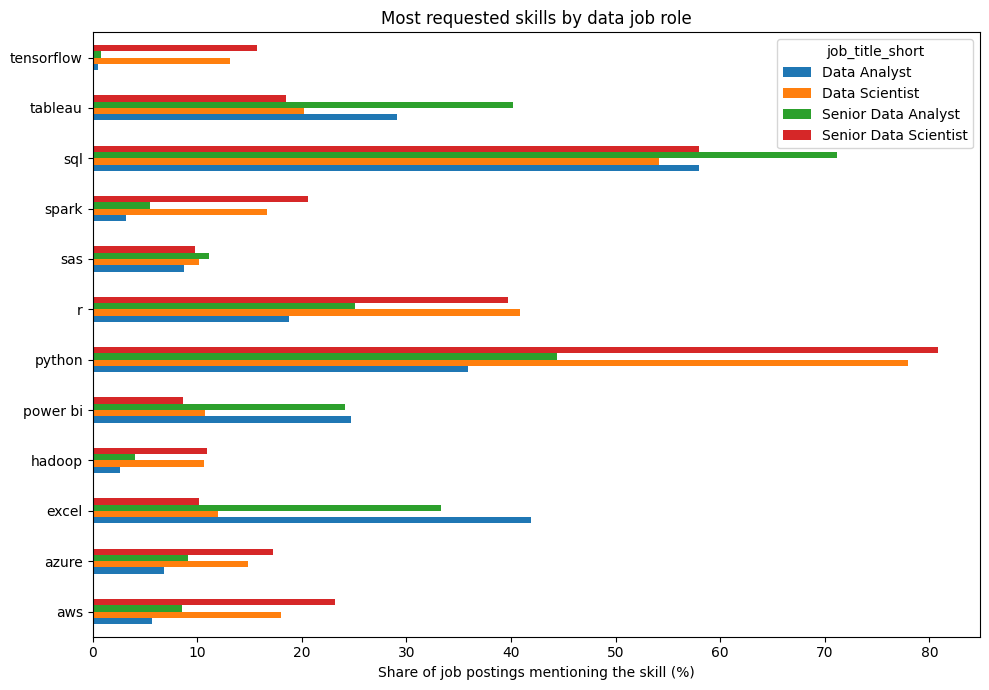

Usable postings: 362147
job_title_short  Data Analyst  Data Scientist  Senior Data Analyst  \
skill                                                                
aws                       5.7            18.0                  8.6   
azure                     6.8            14.9                  9.1   
excel                    41.9            12.0                 33.3   
hadoop                    2.6            10.7                  4.1   
power bi                 24.7            10.8                 24.1   
python                   35.9            78.0                 44.4   
r                        18.8            40.9                 25.1   
sas                       8.8            10.1                 11.1   
spark                     3.2            16.7                  5.5   
sql                      58.0            54.2                 71.2   
tableau                  29.1            20.2                 40.2   
tensorflow                0.5            13.1                  0.8

In [15]:
import ast
import pandas as pd
import matplotlib.pyplot as plt

target_roles = [
    "Data Analyst",
    "Senior Data Analyst",
    "Data Scientist",
    "Senior Data Scientist",
]

jobs = df[df["job_title_short"].isin(target_roles)].copy()

def to_skill_list(value):
    if isinstance(value, list):
        return value
    if pd.isna(value):
        return []
    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else []
    except (ValueError, SyntaxError):
        return []

jobs["skills_list"] = jobs["job_skills"].apply(to_skill_list)
jobs = jobs[jobs["skills_list"].str.len() > 0].copy()

# Give each posting an ID so repeated skills within a posting count once
jobs = jobs.reset_index(drop=True)
jobs["job_id"] = jobs.index

skills = jobs[["job_id", "job_title_short", "skills_list"]].explode("skills_list")
skills = skills.rename(columns={"skills_list": "skill"})
skills = skills.drop_duplicates(subset=["job_id", "skill"])

skill_counts = (
    skills.groupby(["job_title_short", "skill"])
    .size()
    .rename("postings")
    .reset_index()
)

role_totals = jobs.groupby("job_title_short").size()
skill_counts["percent_of_postings"] = skill_counts.apply(
    lambda row: 100 * row["postings"] / role_totals[row["job_title_short"]],
    axis=1,
)

top_skills = (
    skill_counts.groupby("skill")["percent_of_postings"]
    .mean()
    .nlargest(12)
    .index
)

chart_data = (
    skill_counts[skill_counts["skill"].isin(top_skills)]
    .pivot(index="skill", columns="job_title_short", values="percent_of_postings")
    .fillna(0)
)

chart_data.plot(kind="barh", figsize=(10, 7))
plt.title("Most requested skills by data job role")
plt.xlabel("Share of job postings mentioning the skill (%)")
plt.ylabel("")
plt.tight_layout()
plt.show()

print("Usable postings:", len(jobs))
print(chart_data.round(1))

## Remote work by role

Compare the share of postings marked as remote for each role. These figures describe only the postings in this dataset.

                       postings  remote_percent
job_title_short                                
Senior Data Scientist     32076            11.0
Data Scientist           145807             8.8
Senior Data Analyst       24870             8.8
Data Analyst             159394             7.2


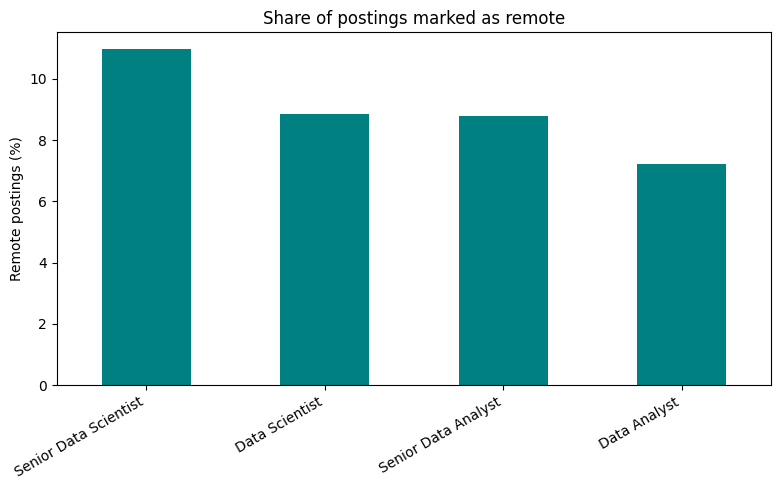

In [16]:
remote_summary = (
    jobs.groupby("job_title_short")
    .agg(
        postings=("job_work_from_home", "size"),
        remote_percent=("job_work_from_home", lambda x: 100 * x.mean()),
    )
    .sort_values("remote_percent", ascending=False)
)

print(remote_summary.round(1))

remote_summary["remote_percent"].plot(
    kind="bar",
    figsize=(8, 5),
    color="teal",
)
plt.title("Share of postings marked as remote")
plt.ylabel("Remote postings (%)")
plt.xlabel("")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## Countries represented

Show the countries with the most postings for each role. These are counts in this dataset, not a ranking of the overall job market.

In [17]:
country_counts = (
    jobs.dropna(subset=["job_country"])
    .groupby(["job_title_short", "job_country"])
    .size()
    .rename("postings")
    .reset_index()
)

for role in country_counts["job_title_short"].unique():
    print(f"\nTop countries for {role}:")
    print(
        country_counts[country_counts["job_title_short"] == role]
        .nlargest(5, "postings")[["job_country", "postings"]]
        .to_string(index=False)
    )


Top countries for Data Analyst:
   job_country  postings
 United States     57391
        France     11237
United Kingdom      8207
     Singapore      5837
       Germany      5282

Top countries for Data Scientist:
   job_country  postings
 United States     51621
         India     11504
        France      7795
United Kingdom      7695
         Sudan      7442

Top countries for Senior Data Analyst:
   job_country  postings
 United States     10428
United Kingdom      1120
     Singapore       997
       Germany       959
         India       943

Top countries for Senior Data Scientist:
   job_country  postings
 United States     11622
         India      2221
United Kingdom      2046
         Sudan      1674
       Germany      1477


## Summary tables

In [18]:
for role in skill_counts["job_title_short"].unique():
    print(f"\nTop skills for {role}:")
    print(
        skill_counts[skill_counts["job_title_short"] == role]
        .nlargest(5, "percent_of_postings")[
            ["skill", "postings", "percent_of_postings"]
        ]
        .round(1)
        .to_string(index=False)
    )

print("\nRemote share by role (%):")
print(remote_summary[["postings", "remote_percent"]].round(1))


Top skills for Data Analyst:
   skill  postings  percent_of_postings
     sql     92428                 58.0
   excel     66860                 41.9
  python     57190                 35.9
 tableau     46455                 29.1
power bi     39380                 24.7

Top skills for Data Scientist:
  skill  postings  percent_of_postings
 python    113711                 78.0
    sql     78982                 54.2
      r     59566                 40.9
tableau     29445                 20.2
    aws     26256                 18.0

Top skills for Senior Data Analyst:
  skill  postings  percent_of_postings
    sql     17709                 71.2
 python     11051                 44.4
tableau      9989                 40.2
  excel      8289                 33.3
      r      6234                 25.1

Top skills for Senior Data Scientist:
 skill  postings  percent_of_postings
python     25915                 80.8
   sql     18605                 58.0
     r     12724                 39.7
  

## Key findings

- Data Analyst postings most often listed **SQL (58.0%)**, **Excel (41.9%)**, and **Python (35.9%)**.
- Data Scientist postings most often listed **Python (78.0%)**, **SQL (54.2%)**, and **R (40.9%)**.
- Remote postings made up **7.2%–11.0%** of the four role groups; Senior Data Scientist postings had the highest share (**11.0%**).
- The **United States** was the most represented country in each selected role group.

These results describe the 2023 postings in this dataset that include skill information. They are not a ranking of the entire or current job market.